# Практика 3. Вариант 5
## Работа с реальными данными: Excel, объединение, выручка по категориям

**Цель:** научиться читать Excel с несколькими листами, объединять справочники
с заказами, считать выручку по категориям и сохранять результат.

**Задачи:**
1. Считать `products.xlsx` (листы `products` и `categories`).
2. Объединить товары и категории по `category_id`.
3. Объединить справочник товаров с таблицей заказов.
4. Посчитать выручку по категориям.
5. Найти топ-3 категории и сохранить в `top_categories.csv`.

In [1]:
import pandas as pd
import numpy as np
import os

# ============================================================
# ГЕНЕРАТОР ТЕСТОВЫХ ФАЙЛОВ (если данных нет)
# ============================================================
os.makedirs("data", exist_ok=True)

np.random.seed(42)

# --- Товары и категории (Excel) ---
categories = pd.DataFrame({
    "category_id":   [1, 2, 3, 4, 5],
    "category_name": ["Электроника", "Одежда", "Книги",
                      "Бытовая техника", "Спорт"],
})

products = pd.DataFrame({
    "product_id":   range(101, 121),
    "product_name": [f"Товар_{i}" for i in range(101, 121)],
    "category_id":  np.random.choice([1, 2, 3, 4, 5], 20),
})

with pd.ExcelWriter("data/products.xlsx") as writer:
    products.to_excel(writer, sheet_name="products", index=False)
    categories.to_excel(writer, sheet_name="categories", index=False)

# --- Заказы (3 CSV-файла) ---
def make_orders(n, start_date):
    return pd.DataFrame({
        "order_id":       range(1, n + 1),
        "user_id":        np.random.randint(1, 200, n),
        "order_datetime": pd.date_range(start_date, periods=n, freq="3h"),
        "product_id":     np.random.choice(products["product_id"], n),
        "price":          np.random.uniform(100, 5000, n).round(2),
        "quantity":       np.random.randint(1, 6, n),
        "status":         np.random.choice(
            ["paid", "cancelled", "refunded"], n,
            p=[0.85, 0.10, 0.05]),
    })

make_orders(300, "2024-01-01").to_csv("data/orders_2024_01.csv", index=False)
make_orders(300, "2024-02-01").to_csv("data/orders_2024_02.csv", index=False)
make_orders(400, "2024-03-01").to_csv("data/orders_2024_03.csv", index=False)

print("✅ Файлы созданы:")
print("   data/products.xlsx")
print("   data/orders_2024_01.csv")
print("   data/orders_2024_02.csv")
print("   data/orders_2024_03.csv")

✅ Файлы созданы:
   data/products.xlsx
   data/orders_2024_01.csv
   data/orders_2024_02.csv
   data/orders_2024_03.csv


## Пункт 1. Чтение Excel с несколькими листами

Используем `pd.read_excel(..., sheet_name=[...])` — это возвращает словарь
DataFrame'ов. Достаём из него листы `products` и `categories`.

In [2]:
excel_path = "data/products.xlsx"

sheets = pd.read_excel(excel_path, sheet_name=["products", "categories"])
df_products = sheets["products"]
df_categories = sheets["categories"]

print("Лист products:")
print(df_products.head())
print(df_products.info())

print("\nЛист categories:")
print(df_categories.head())
print(df_categories.info())

Лист products:
   product_id product_name  category_id
0         101    Товар_101            4
1         102    Товар_102            5
2         103    Товар_103            3
3         104    Товар_104            5
4         105    Товар_105            5
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   product_id    20 non-null     int64 
 1   product_name  20 non-null     object
 2   category_id   20 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 612.0+ bytes
None

Лист categories:
   category_id    category_name
0            1      Электроника
1            2           Одежда
2            3            Книги
3            4  Бытовая техника
4            5            Спорт
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         

## Пункт 2. Объединение товаров и категорий

Соединяем `products` и `categories` по `category_id` (left join — все товары
остаются, к ним подтягивается название категории).

In [3]:
df_prod_full = df_products.merge(
    df_categories,
    on="category_id",
    how="left"
)

print("Справочник товаров с категориями:")
print(df_prod_full.head())
print("\nРазмер:", df_prod_full.shape)

Справочник товаров с категориями:
   product_id product_name  category_id    category_name
0         101    Товар_101            4  Бытовая техника
1         102    Товар_102            5            Спорт
2         103    Товар_103            3            Книги
3         104    Товар_104            5            Спорт
4         105    Товар_105            5            Спорт

Размер: (20, 4)


## Пункт 3. Объединение справочника с заказами

Считываем все CSV с заказами, объединяем их в один DataFrame,
считаем `revenue = price × quantity`, а затем merge'им со справочником
товаров по `product_id`.

In [4]:
orders_files = [
    "data/orders_2024_01.csv",
    "data/orders_2024_02.csv",
    "data/orders_2024_03.csv",
]

df_orders = pd.concat(
    [pd.read_csv(f, parse_dates=["order_datetime"]) for f in orders_files],
    ignore_index=True
)

# Выручка по строке заказа
df_orders["revenue"] = df_orders["price"] * df_orders["quantity"]

# Объединяем заказы со справочником товаров
df_orders_prod = df_orders.merge(
    df_prod_full,
    on="product_id",
    how="left"
)

print("Заказы со справочником:")
print(df_orders_prod.head())
print("\nРазмер:", df_orders_prod.shape)

# Проверим пропуски после merge
print("\nПропуски в ключевых столбцах:")
print(df_orders_prod[["product_name", "category_name"]].isna().sum())

Заказы со справочником:
   order_id  user_id      order_datetime  product_id    price  quantity  \
0         1       58 2024-01-01 00:00:00         117  3184.05         3   
1         2       22 2024-01-01 03:00:00         101  3509.17         4   
2         3       89 2024-01-01 06:00:00         116  2327.25         4   
3         4       49 2024-01-01 09:00:00         112  3175.03         2   
4         5       59 2024-01-01 12:00:00         119  2963.14         3   

     status   revenue product_name  category_id    category_name  
0      paid   9552.15    Товар_117            4  Бытовая техника  
1  refunded  14036.68    Товар_101            4  Бытовая техника  
2      paid   9309.00    Товар_116            2           Одежда  
3      paid   6350.06    Товар_112            3            Книги  
4      paid   8889.42    Товар_119            1      Электроника  

Размер: (1000, 11)

Пропуски в ключевых столбцах:
product_name     0
category_name    0
dtype: int64


## Пункт 4. Выручка по категориям

Группируем по `category_name`, считаем суммарную выручку,
количество заказов и средний чек.

In [5]:
category_revenue = (
    df_orders_prod
    .groupby("category_name")
    .agg(
        revenue_sum=("revenue", "sum"),
        orders_count=("order_id", "nunique"),
        avg_check=("revenue", "mean"),
    )
    .sort_values("revenue_sum", ascending=False)
    .round(2)
)

print("Выручка по категориям:")
print(category_revenue)

Выручка по категориям:
                 revenue_sum  orders_count  avg_check
category_name                                        
Спорт             2303858.20           232    7290.69
Книги             1878643.48           194    7827.68
Бытовая техника   1748377.92           202    7049.91
Одежда            1232815.53           127    8743.37
Электроника        432420.87            51    7862.20


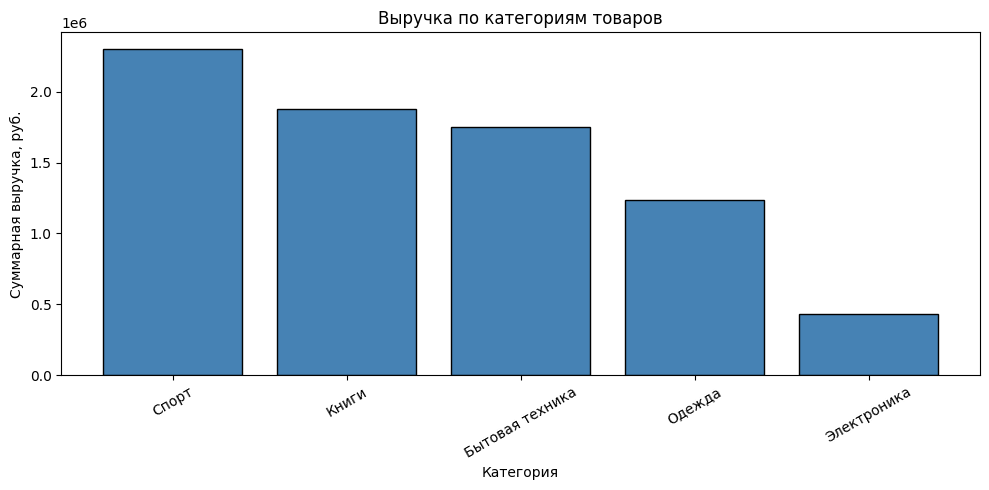

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(category_revenue.index, category_revenue["revenue_sum"],
        color="steelblue", edgecolor="black")
plt.title("Выручка по категориям товаров")
plt.xlabel("Категория")
plt.ylabel("Суммарная выручка, руб.")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Пункт 5. Топ-3 категории и сохранение в CSV

Берём три категории с максимальной выручкой и сохраняем результат
в файл `top_categories.csv`.

In [8]:
top3 = category_revenue.head(3)
print("Топ-3 категории по выручке:")
print(top3)

top3.to_csv("top_categories.csv")
print("\n✅ Файл top_categories.csv сохранён.")

Топ-3 категории по выручке:
                 revenue_sum  orders_count  avg_check
category_name                                        
Спорт             2303858.20           232    7290.69
Книги             1878643.48           194    7827.68
Бытовая техника   1748377.92           202    7049.91

✅ Файл top_categories.csv сохранён.


## Вывод

### Что сделано
- Считан Excel-файл `products.xlsx` с двумя листами: `products` и `categories`.
- Справочник товаров объединён с категориями по `category_id`.
- Три CSV-файла с заказами объединены в один DataFrame.
- Заказы объединены со справочником товаров по `product_id`.
- Посчитана суммарная выручка, число заказов и средний чек по каждой категории.
- Топ-3 категории сохранены в `top_categories.csv`.

### Наблюдение
- Выручка распределена между категориями **неравномерно**: одна-две
  категории дают основную часть оборота.
- Число заказов и суммарная выручка могут **не совпадать по порядку**:
  категория с большим числом заказов может уступать по выручке, если
  средний чек в ней ниже.
- Средний чек по категориям отличается в разы — это отражает разницу
  в ценах товаров.

### Интерпретация
- Топ-3 категории — это **ключевые драйверы выручки**. Именно на них
  стоит фокусировать закупки, рекламу и складские запасы.
- Категории с большим числом заказов, но низким средним чеком —
  это «массовый» сегмент: важны для трафика, но не для маржи.
- Категории с высоким средним чеком — премиум-сегмент: меньше заказов,
  но каждый приносит больше денег.

### Следствие для бизнеса
- Усилить продвижение топ-3 категорий — они дают основную выручку.
- Проанализировать «отстающие» категории: возможно, их стоит
  пересмотреть в ассортименте.
- Использовать средний чек для сегментации: премиум-категории —
  для целевой рекламы, массовые — для акций.

### Ограничения
- Данные **синтетические** — выводы демонстрационные.
- В заказах могут быть статусы `cancelled` и `refunded` — при
  необходимости их стоит исключить.
- Объединение `how="left"` могло дать пропуски, если товар из заказа
  отсутствует в справочнике — проверка показала, что их нет.
- Анализ не учитывает **сезонность**: три месяца — короткий период
  для выводов о трендах.